# Laboratory Work 2 — Fuzzy Inference Systems with Scikit-Fuzzy
## Choose the washing time
**Course:** AI: Fundamentals and Applications  
**Task file:** lab_2_ai_fuzzy.pdf. Chosen topic: Washing Machine Control.

**Aim:** build a fuzzy system that chooses a washing time.
It uses two inputs: how dirty the clothes are and how much they weigh.
It has one output: washing time.
Each variable has three fuzzy sets. The system has nine rules.

A fuzzy set lets a value be partly low, medium, or high.
For example, clothes can be medium dirty with a value of 0.6
and very dirty with a value of 0.4 at the same time.

This notebook has code, results, plots, and a short report.
The report is in section 8.

**How to run:** open the notebook in Google Colab or Jupyter.
Run all cells from top to bottom.
The first code cell installs missing libraries if needed.

## 1. Libraries

In [1]:
import importlib.util
import subprocess
import sys

required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "scipy": "scipy", "networkx": "networkx", "skfuzzy": "scikit-fuzzy"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from IPython.display import display, Markdown
from importlib.metadata import version

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
print("Python:", sys.version.split()[0])
for package in required.values():
    print(f"{package}: {version(package)}")

Python: 3.14.3
numpy: 2.5.3
pandas: 3.0.5
matplotlib: 3.11.2
scipy: 1.18.1
networkx: 3.7
scikit-fuzzy: 0.5.0


## 2. Variables and membership functions

A membership value tells us how well a number fits a fuzzy set.
It is between 0 and 1. A membership function calculates this value.

| Variable | Type | Range | Sets and `trimf` values |
|---|---|---|---|
| `dirtiness` — how dirty the clothes are | Input | 0–100 points | low `[0,0,50]`, medium `[0,50,100]`, high `[50,100,100]` |
| `load_weight` — weight of the clothes | Input | 0–10 kg | light `[0,0,5]`, medium `[0,5,10]`, heavy `[5,10,10]` |
| `washing_time` — washing time | Output | 10–90 min | short `[10,10,50]`, medium `[10,50,90]`, long `[50,90,90]` |

We use triangle-shaped functions. Three values $(a,b,c)$ give their shape.
The membership is 1 at $b$. It goes up from $a$ to $b$ and down from $b$ to $c$.
At the two ends of a range, we use `a=b` or `b=c`.
This keeps a membership of 1 at the end point.

Nearby sets overlap: one value can belong to two sets.
At every point in each range, at least one set has a membership above zero.

In [2]:
dirtiness = ctrl.Antecedent(np.arange(0, 101, 1), "dirtiness")
load_weight = ctrl.Antecedent(np.linspace(0, 10, 101), "load_weight")
washing_time = ctrl.Consequent(np.arange(10, 91, 1), "washing_time")
washing_time.defuzzify_method = "centroid"

membership_parameters = [
    (dirtiness, {"low": [0, 0, 50], "medium": [0, 50, 100], "high": [50, 100, 100]}),
    (load_weight, {"light": [0, 0, 5], "medium": [0, 5, 10], "heavy": [5, 10, 10]}),
    (washing_time, {"short": [10, 10, 50], "medium": [10, 50, 90], "long": [50, 90, 90]}),
]
for variable, terms in membership_parameters:
    for name, parameters in terms.items():
        variable[name] = fuzz.trimf(variable.universe, parameters)
    coverage = np.vstack([term.mf for term in variable.terms.values()])
    assert np.all(coverage.max(axis=0) > 0), f"A point has no active set: {variable.label}"
    assert np.all((coverage >= 0) & (coverage <= 1))
print("Created 2 inputs and 1 output, with 3 sets each. All ranges are covered.")

Created 2 inputs and 1 output, with 3 sets each. All ranges are covered.


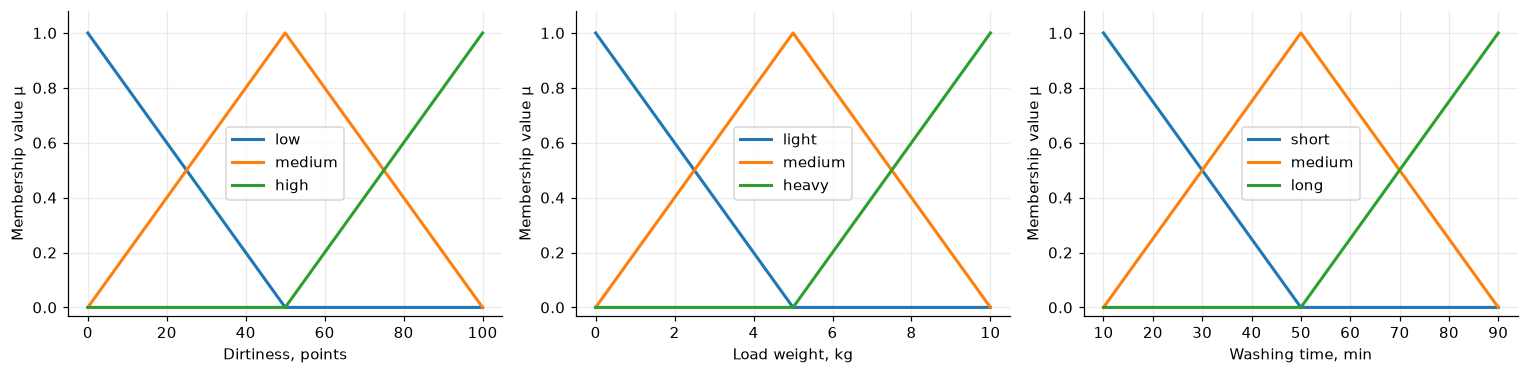

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
labels = ["Dirtiness, points", "Load weight, kg", "Washing time, min"]
for ax, (variable, _), label in zip(axes, membership_parameters, labels):
    for name, term in variable.terms.items():
        ax.plot(variable.universe, term.mf, linewidth=2, label=name)
    ax.set(xlabel=label, ylabel="Membership value μ", ylim=(-0.03, 1.08))
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Nine fuzzy rules

Each table cell gives the output of a rule:
**IF dirtiness is … AND load_weight is … THEN washing_time is …**.

| Dirtiness / Weight | light | medium | heavy |
|---|---|---|---|
| low | short (R1) | short (R2) | medium (R3) |
| medium | short (R4) | medium (R5) | long (R6) |
| high | medium (R7) | long (R8) | long (R9) |

The main idea is simple: more dirt and more clothes usually need more time.
For a light load with medium dirt, we choose short.
For a light load with high dirt, we choose medium.
These are our choices for this study.

We use the Mamdani method. It has these steps:

1. Find the membership values of both inputs.
2. For AND, take the smaller value. This is the rule strength.
3. Cut the output set at this strength.
4. Join the output sets by taking the largest value at each point.
5. Find the centre of the joined area. This gives one time in minutes.

The last step is called **centroid defuzzification**:
$t^*=\frac{\int t\mu_{\rm agg}(t)dt}{\int\mu_{\rm agg}(t)dt}$.
It is like finding the balance point of the area.

In [4]:
rule_specs = [
    ("R1", "low", "light", "short"),
    ("R2", "low", "medium", "short"),
    ("R3", "low", "heavy", "medium"),
    ("R4", "medium", "light", "short"),
    ("R5", "medium", "medium", "medium"),
    ("R6", "medium", "heavy", "long"),
    ("R7", "high", "light", "medium"),
    ("R8", "high", "medium", "long"),
    ("R9", "high", "heavy", "long"),
]
rules = [
    ctrl.Rule(dirtiness[dirt_term] & load_weight[load_term],
              washing_time[time_term], label=label)
    for label, dirt_term, load_term, time_term in rule_specs
]
washing_system = ctrl.ControlSystem(rules)
display(pd.DataFrame(rule_specs, columns=["Rule", "dirtiness", "load_weight",
                                          "washing_time"]))

def simulate_wash(dirt, weight):
    if not (np.isfinite(dirt) and np.isfinite(weight)
            and 0 <= dirt <= 100 and 0 <= weight <= 10):
        raise ValueError("Use dirtiness in [0,100] and load_weight in [0,10]")
    simulation = ctrl.ControlSystemSimulation(washing_system, clip_to_bounds=False)
    simulation.input["dirtiness"] = float(dirt)
    simulation.input["load_weight"] = float(weight)
    simulation.compute()
    return float(simulation.output["washing_time"]), simulation

def rule_activations(dirt, weight):
    rows = []
    for label, dirt_term, load_term, time_term in rule_specs:
        mu_dirt = float(fuzz.interp_membership(
            dirtiness.universe, dirtiness[dirt_term].mf, dirt))
        mu_load = float(fuzz.interp_membership(
            load_weight.universe, load_weight[load_term].mf, weight))
        rows.append({"Rule": label, "Dirt set": dirt_term,
                     "Weight set": load_term, "Output": time_term,
                     "Dirt membership": mu_dirt, "Weight membership": mu_load,
                     "Strength": min(mu_dirt, mu_load)})
    return pd.DataFrame(rows)

,Rule,dirtiness,load_weight,washing_time
0,R1,low,light,short
1,R2,low,medium,short
2,R3,low,heavy,medium
3,R4,medium,light,short
4,R5,medium,medium,medium
5,R6,medium,heavy,long
6,R7,high,light,medium
7,R8,high,medium,long
8,R9,high,heavy,long


## 4. Test different inputs

We test low, medium, and high values.
We also test the ends of the ranges and points where sets overlap.

In [5]:
cases = [
    ("Smallest inputs", 0, 0),
    ("Low dirt, light load", 10, 1),
    ("Low dirt, heavy load", 10, 9),
    ("Middle values", 50, 5),
    ("High dirt, light load", 90, 1),
    ("High dirt, heavy load", 90, 9),
    ("Overlapping sets", 70, 6),
    ("Largest inputs", 100, 10),
]
simulation_rows = []
for description, dirt, weight in cases:
    value, _ = simulate_wash(dirt, weight)
    active = rule_activations(dirt, weight).query("Strength > 0")
    active_text = ", ".join(f'{r["Rule"]}={r["Strength"]:.2f}'
                            for _, r in active.iterrows())
    simulation_rows.append({"Example": description, "Dirtiness": dirt,
                            "Weight, kg": weight, "Time, min": value,
                            "Active rules": active_text})
simulation_results = pd.DataFrame(simulation_rows)
display(simulation_results.round(3))
assert np.isfinite(simulation_results["Time, min"]).all()
assert simulation_results["Time, min"].between(10, 90).all()
np.testing.assert_allclose(simulation_results.loc[3, "Time, min"], 50, atol=1e-8)

,Example,Dirtiness,"Weight, kg","Time, min",Active rules
0,Smallest inputs,0,0,23.333,R1=1.00
1,"Low dirt, light load",10,1,36.196,"R1=0.80, R2=0.20, R4=0.20, R5=0.20"
2,"Low dirt, heavy load",10,9,50.000,"R2=0.20, R3=0.80, R5=0.20, R6=0.20"
3,Middle values,50,5,50.000,R5=1.00
4,"High dirt, light load",90,1,50.000,"R4=0.20, R5=0.20, R7=0.80, R8=0.20"
5,"High dirt, heavy load",90,9,63.804,"R5=0.20, R6=0.20, R8=0.20, R9=0.80"
6,Overlapping sets,70,6,53.014,"R5=0.60, R6=0.20, R8=0.40, R9=0.20"
7,Largest inputs,100,10,76.667,R9=1.00


## 5. Check rule strengths by hand

For `dirtiness=70` and `load_weight=6`:

- Dirt: $\mu_{\rm medium}=(100-70)/50=0.6$,
  $\mu_{\rm high}=(70-50)/50=0.4$.
- Weight: $\mu_{\rm medium}=(10-6)/5=0.8$,
  $\mu_{\rm heavy}=(6-5)/5=0.2$.
- R5 gives medium: $\min(0.6,0.8)=0.6$.
- R6 gives long: $\min(0.6,0.2)=0.2$.
- R8 gives long: $\min(0.4,0.8)=0.4$.
- R9 gives long: $\min(0.4,0.2)=0.2$.

So we cut the medium output set at 0.6.
For long, we use the largest strength: $\max(0.2,0.4,0.2)=0.4$.
No rule gives short for this example.

A strength of 0.6 does not mean 60 minutes or a 60% chance.
It tells us how strongly the rule is active.

,Rule,Dirt set,Weight set,Output,Dirt membership,Weight membership,Strength
0,R1,low,light,short,0.0,0.0,0.0
1,R2,low,medium,short,0.0,0.8,0.0
2,R3,low,heavy,medium,0.0,0.2,0.0
3,R4,medium,light,short,0.6,0.0,0.0
4,R5,medium,medium,medium,0.6,0.8,0.6
5,R6,medium,heavy,long,0.6,0.2,0.2
6,R7,high,light,medium,0.4,0.0,0.0
7,R8,high,medium,long,0.4,0.8,0.4
8,R9,high,heavy,long,0.4,0.2,0.2


Result for (70, 6): 53.014 min


/Users/turarbeksatbaldiyev/Desktop/codespace/huawei/.venv/lib/python3.14/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


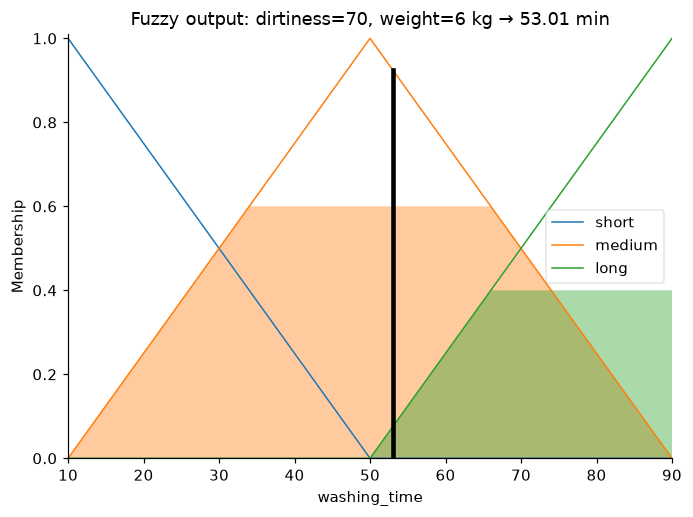

In [6]:
selected_dirt, selected_weight = 70, 6
activation_table = rule_activations(selected_dirt, selected_weight)
display(activation_table.round(3))
actual_strengths = activation_table.set_index("Rule")["Strength"]
np.testing.assert_allclose(actual_strengths.loc[["R5", "R6", "R8", "R9"]],
                           [0.6, 0.2, 0.4, 0.2])
selected_time, selected_sim = simulate_wash(selected_dirt, selected_weight)
for rule in rules:
    np.testing.assert_allclose(float(rule.aggregate_firing[selected_sim]),
                               actual_strengths[rule.label], atol=1e-12)
print(f"Result for (70, 6): {selected_time:.3f} min")
washing_time.view(sim=selected_sim)
plt.title(f"Fuzzy output: dirtiness=70, weight=6 kg → {selected_time:.2f} min")
plt.tight_layout()
plt.show()

## 6. Output plots for four examples

The coloured area shows the joined output sets after we cut them.
The vertical line shows the final time from Scikit-Fuzzy.

We use many small steps to draw the area.
We also calculate its centre in a second way and compare the two answers.

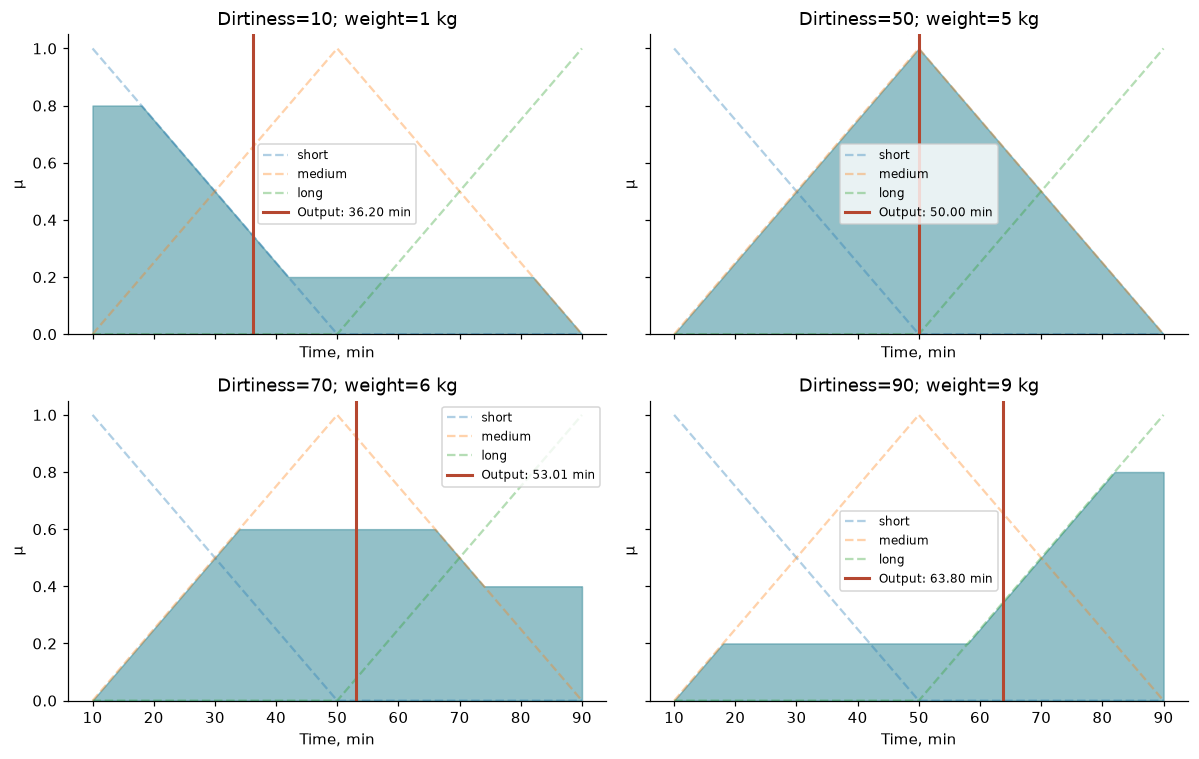

The two centre-of-area calculations agree.


In [7]:
def aggregate_output(dirt, weight, universe):
    table = rule_activations(dirt, weight)
    aggregated = np.zeros_like(universe, dtype=float)
    for term_name, term in washing_time.terms.items():
        strength = table.loc[table["Output"] == term_name, "Strength"].max()
        membership = fuzz.interp_membership(washing_time.universe, term.mf, universe)
        aggregated = np.maximum(aggregated, np.minimum(strength, membership))
    return aggregated

plot_cases = [(10, 1), (50, 5), (70, 6), (90, 9)]
fine_time = np.linspace(10, 90, 8001)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (dirt, weight) in zip(axes.flat, plot_cases):
    result, _ = simulate_wash(dirt, weight)
    aggregated = aggregate_output(dirt, weight, fine_time)
    manual_centroid = fuzz.defuzz(fine_time, aggregated, "centroid")
    np.testing.assert_allclose(manual_centroid, result, atol=0.02)
    for name, term in washing_time.terms.items():
        ax.plot(washing_time.universe, term.mf, "--", alpha=0.35, label=name)
    ax.fill_between(fine_time, aggregated, color="#4b96a4", alpha=0.6)
    ax.axvline(result, color="#b54730", linewidth=2, label=f"Output: {result:.2f} min")
    ax.set_title(f"Dirtiness={dirt}; weight={weight} kg")
    ax.set(xlabel="Time, min", ylabel="μ", ylim=(0, 1.05))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("The two centre-of-area calculations agree.")

## 7. How each input changes the output

We test a grid with 21 dirt values and 21 weight values.
That gives 441 input pairs.
We check that the system gives an answer for every pair.

The line plot shows what happens when dirt changes but weight stays the same.
The rules suggest a general rise in time.
However, the centre-of-area method can also give small local falls.
We measure these falls below.

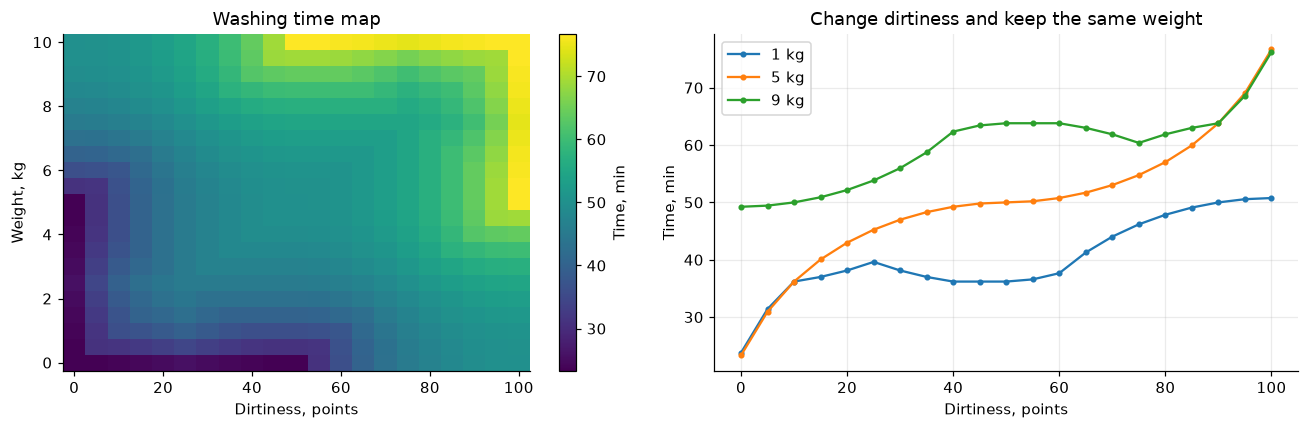

Checked 441 input pairs. Range: 23.333–76.667 min.
Largest local fall when dirtiness rises by 5: 1.494 min.
Largest local fall when weight rises by 0.5 kg: 1.494 min.


In [8]:
dirt_grid = np.linspace(0, 100, 21)
weight_grid = np.linspace(0, 10, 21)
surface = np.empty((len(weight_grid), len(dirt_grid)))
for i, weight in enumerate(weight_grid):
    for j, dirt in enumerate(dirt_grid):
        surface[i, j], _ = simulate_wash(dirt, weight)
assert np.isfinite(surface).all() and np.all((surface >= 10) & (surface <= 90))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
mesh = axes[0].pcolormesh(dirt_grid, weight_grid, surface, shading="auto", cmap="viridis")
axes[0].set(xlabel="Dirtiness, points", ylabel="Weight, kg",
            title="Washing time map")
fig.colorbar(mesh, ax=axes[0], label="Time, min")
for weight in [1, 5, 9]:
    values = [simulate_wash(dirt, weight)[0] for dirt in dirt_grid]
    axes[1].plot(dirt_grid, values, marker=".", label=f"{weight} kg")
axes[1].set(xlabel="Dirtiness, points", ylabel="Time, min",
            title="Change dirtiness and keep the same weight")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

negative_dirt_steps = np.diff(surface, axis=1)
negative_weight_steps = np.diff(surface, axis=0)
print(f"Checked {surface.size} input pairs. Range: "
      f"{surface.min():.3f}–{surface.max():.3f} min.")
print(f"Largest local fall when dirtiness rises by 5: "
      f"{max(0.0, -negative_dirt_steps.min()):.3f} min.")
print(f"Largest local fall when weight rises by 0.5 kg: "
      f"{max(0.0, -negative_weight_steps.min()):.3f} min.")

## 8. Short report

### 8.1. Problem and main choices

We want to choose a washing time from two facts: how dirty the clothes are
and how much they weigh. A simple system can use fixed limits.
However, a very small input change near a limit can then give a very different
washing time. A fuzzy system can describe values between low, medium, and high.
It uses several rules together to give one answer.

We use dirtiness from 0 to 100 points and weight from 0 to 10 kg.
The output range is 10 to 90 minutes. These ranges are choices for our example.
The system does not learn from data. We choose its sets and rules ourselves.
This makes the system easy to explain: we can see which rules give each answer.

We include 0 kg to test the end of the range. A real machine should use a
separate check before it starts with no clothes. Our model only uses dirt and
weight. It does not use the type of cloth, water temperature, or washing product.
These other facts can also change the time needed.

### 8.2. Inputs, output, and fuzzy sets

Each variable has three sets. Dirtiness has low, medium, and high.
Weight has light, medium, and heavy. Time has short, medium, and long.
Section 2 gives all the triangle values. The middle points are 50 dirt points,
5 kg, and 50 minutes.

We choose triangles because they are easy to draw and check by hand.
The first and last sets cover the ends of each range.
The program checks that every point belongs to at least one set.
This is important: an input must activate a rule so the system can give an answer.

Nearby sets overlap. For example, 70 dirt points has medium membership 0.6
and high membership 0.4. These are degrees of membership, not probabilities.
In this design, nearby input memberships add up to 1.
Other fuzzy systems do not have to follow this rule.
The overlap lets more than one rule affect the answer.

### 8.3. Rules and the calculation

There are nine rules, one for each pair of input sets.
Section 3 shows the full rule table.
Low dirt and low weight give short time.
High dirt and high weight give long time.
Other pairs give short, medium, or long time as shown in the table.

For medium dirt and a light load, we choose short time.
This is a choice for our study, not a fact proved by washing tests.
We could change it later if real tests show that more time is needed.
The same is true for the triangle shapes.

The program uses Scikit-Fuzzy.
`Antecedent` defines an input and `Consequent` defines an output.
`Rule` stores each rule. `ControlSystem` joins the rules.
`ControlSystemSimulation` gets the input values, and `compute()` finds the output.

AND takes the smaller membership value.
We cut each output set at the rule strength.
If several rules give the same output set, we use the largest strength.
We do not add the strengths.
We join the cut sets and find the centre of the area.
This gives one number in minutes.
The program rejects inputs outside the given ranges.

### 8.4. Test examples

We test eight examples. They include the smallest and largest inputs,
middle inputs, and different dirt and weight pairs.
We also test a point where several sets overlap.
Section 4 shows the time and active rules for each example.

We then test 441 pairs on a grid.
We check that every result is a real number between 10 and 90 minutes.
The next list uses the actual results from the program.

In [9]:
lookup = {(row["Dirtiness"], row["Weight, kg"]): row["Time, min"]
          for _, row in simulation_results.iterrows()}
display(Markdown(
    f'- At (10 points, 1 kg): **{lookup[(10, 1)]:.3f} min**; '
    f'at (10 points, 9 kg): **{lookup[(10, 9)]:.3f} min**.\n'
    f'- At (90 points, 1 kg): **{lookup[(90, 1)]:.3f} min**; '
    f'at (90 points, 9 kg): **{lookup[(90, 9)]:.3f} min**.\n'
    f'- Middle inputs (50, 5) give **{lookup[(50, 5)]:.3f} min**.\n'
    f'- At (70, 6), sets overlap. The time is **{selected_time:.3f} min**. '
    'Active rules: R5=0.6, R6=0.2, R8=0.4, and R9=0.2.\n'
    f'- The end points (0, 0) and (100, 10) give '
    f'**{lookup[(0, 0)]:.3f} min** and **{lookup[(100, 10)]:.3f} min**.'
))

- At (10 points, 1 kg): **36.196 min**; at (10 points, 9 kg): **50.000 min**.
- At (90 points, 1 kg): **50.000 min**; at (90 points, 9 kg): **63.804 min**.
- Middle inputs (50, 5) give **50.000 min**.
- At (70, 6), sets overlap. The time is **53.014 min**. Active rules: R5=0.6, R6=0.2, R8=0.4, and R9=0.2.
- The end points (0, 0) and (100, 10) give **23.333 min** and **76.667 min**.

### 8.5. What the results show

In our low-dirt and high-dirt examples, a heavier load gives more washing time.
More dirt also gives a general rise in time.
At (50, 5), only the middle rule is active.
The output triangle is the same on both sides of 50, so the answer is 50 minutes.

At (0, 0), the answer is not 10 minutes.
The centre of the short triangle `[10,10,50]` is 23.333 minutes.
The centre of the long triangle `[50,90,90]` is 76.667 minutes.
So the smallest and largest output-range values are not the same as the
smallest and largest answers.

At (70, 6), both medium and long output sets are active.
The result is a little above 50 minutes.
It depends on the whole joined area, not only on the strongest rule.
We check the rule strengths by hand and compare them with Scikit-Fuzzy.
We also calculate the centre of the area in a second way.
The two answers agree within the small limit used in the code.

Overlap makes the time change without sudden jumps.
However, time does not rise at every small step.
Cutting a triangle at a different height changes its area and its balance point.
Joining several sets can also cause small local falls.
Section 7 measures the largest fall for each input.
This is a limit of our chosen shapes and rules.

The system works with two inputs, one output, and nine rules.
Its answers follow the main idea of the example, and we can explain them.
Before using this model in a real machine, we would need washing tests.
Those tests could help us improve the shapes and rules.
We could add more inputs, but we would also need more rules.

## Sources

- Task: `lab_2_ai_fuzzy.pdf`, Laboratory Work 2, Pakizar Shamoi.
- [Official Scikit-Fuzzy control example](https://scikit-fuzzy.github.io/scikit-fuzzy/auto_examples/plot_tipping_problem_newapi.html).
- [Mamdani example: joining sets and finding one output](https://scikit-fuzzy.github.io/scikit-fuzzy/auto_examples/plot_tipping_problem.html).